<a href="https://colab.research.google.com/github/BitCurrent02/DSP-Course-2026/blob/main/Lecture07-Audio%20Processing%20and%20AI/Lecture07_Option_C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Audio Signal Processing Fundamentals and Introduction to AI for Audio
CPU-only teaching notebook. Open a fresh Google Colab runtime. Upload the supplied course ZIP when asked. Run from top to bottom. Do not run student TODO cells with Run all before the demonstration.

**Outcomes:** inspect audio (LO1), select features (LO2), evaluate processing (LO3), compare classifiers without source leakage (LO4), assess pretrained tools and deployment (LO5).

The supplied classification task uses four recorded environmental classes. The class-recording extension uses clap, snap, speech and background. These are different label vocabularies; never combine them under the same labels. Model downloads require internet. No API key, GPU or microphone is required for the supplied route.


In [1]:
# Single installation cell. Run before importing course libraries.
# Prepare before class: the full model environment is too large for a guaranteed 10-minute setup.
import sys, subprocess, os
assert (3,10) <= sys.version_info[:2] <= (3,12), 'This pinned environment targets Python 3.10–3.12. Use a compatible Colab runtime.'
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_USE_LEGACY_KERAS'] = '1'
subprocess.check_call([sys.executable,'-m','pip','install','-q','torch==2.6.0','torchaudio==2.6.0','--index-url','https://download.pytorch.org/whl/cpu'])
subprocess.check_call([sys.executable,'-m','pip','install','-q','torch==2.6.0','torchaudio==2.6.0','numpy==2.1.3','scipy==1.15.3','matplotlib==3.10.1','pandas==2.2.3','librosa==0.11.0','soundfile==0.13.1','scikit-learn==1.6.1','noisereduce==3.0.3','tensorflow==2.19.0','tf-keras==2.19.0','tensorflow-hub==0.16.1','openai-whisper==20250625','julius==0.2.7'])
print('Installation complete. If Colab requests a restart, restart the session, then continue below. Do not reinstall in the restarted session.')


Installation complete. If Colab requests a restart, restart the session, then continue below. Do not reinstall in the restarted session.


In [1]:
# Load the supplied ZIP once. No microphone is needed.
from pathlib import Path
import os, zipfile
ROOT = Path(os.environ.get('AUDIO_COURSE_ROOT','/content/audio_course'))
if not (ROOT/'data/manifest.csv').exists():
    from google.colab import files
    uploaded = files.upload()
    archives = [n for n in uploaded if n.lower().endswith('.zip')]
    assert len(archives)==1, 'Upload the supplied Audio_Course_Package.zip.'
    ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archives[0]) as z:
        for item in z.infolist():
            destination=(ROOT/item.filename).resolve()
            assert destination.is_relative_to(ROOT.resolve()), 'Unexpected ZIP path.'
        z.extractall(ROOT)
assert (ROOT/'data/manifest.csv').exists(), 'Use the course package ZIP, which contains data/manifest.csv.'
print('Course folder:', ROOT)


Course folder: /content/audio_course


In [2]:
import os, json, time, re, unicodedata, importlib.metadata as meta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
import soundfile as sf
from scipy import signal
from IPython.display import Audio, display

os.environ['CUDA_VISIBLE_DEVICES']='-1'
os.environ['TF_USE_LEGACY_KERAS']='1'
SEED=42
rng=np.random.default_rng(SEED)
FS=16000
DATA=ROOT/'data'
OUT=ROOT/'results'; OUT.mkdir(exist_ok=True)
FIG=OUT/'figures'; FIG.mkdir(exist_ok=True)

def load_audio(path, target_rate=FS):
    x, rate = sf.read(str(path),dtype='float32',always_2d=True)
    x=x.mean(axis=1)  # This course uses mono. Opposite-polarity channels can cancel.
    assert len(x)>0 and np.isfinite(x).all(), 'Invalid audio.'
    if rate != target_rate:
        x=librosa.resample(x,orig_sr=rate,target_sr=target_rate)
    return np.asarray(x,dtype=np.float32)

def play(x, rate=FS):
    display(Audio(np.asarray(x),rate=rate,normalize=False))

def save_plot(name):
    plt.tight_layout(); plt.savefig(FIG/name,dpi=140); plt.show()

def spectrum(x, fs=FS):
    a=np.asarray(x,dtype=float); a=a-a.mean()
    s=np.abs(np.fft.rfft(a*np.hanning(len(a))))
    return np.fft.rfftfreq(len(a),1/fs),20*np.log10(np.maximum(s/max(s.max(),1e-12),1e-6))

def inspect(x, fs=FS, title='Audio', name='inspection.png'):
    f,d=spectrum(x,fs)
    fig,ax=plt.subplots(2,1,figsize=(9,5))
    ax[0].plot(np.arange(len(x))/fs,x,lw=.7);ax[0].set(title=title,xlabel='Time (s)',ylabel='Amplitude')
    ax[1].plot(f,d);ax[1].set(xlabel='Frequency (Hz)',ylabel='Relative magnitude (dB)',xlim=(0,min(5000,fs/2)),ylim=(-80,3))
    save_plot(name)

versions={n:meta.version(n) for n in ['numpy','scipy','librosa','soundfile','scikit-learn','noisereduce','torch','torchaudio','tensorflow','tensorflow-hub','openai-whisper']}
(OUT/'environment.json').write_text(json.dumps({'seed':SEED,'versions':versions},indent=2))
speech=load_audio(DATA/'demo/05_speech.wav')
print('Speech duration:',len(speech)/FS,'seconds')
play(speech)


Speech duration: 11.0 seconds


In [ ]:
# TODO


## Block 1: the audio signal and its spectrum (10–45 minutes)
A waveform shows amplitude over time. A spectrum shows frequency content in a selected interval. Sampling can introduce aliasing when high frequencies enter without suitable filtering. Bit depth describes amplitude resolution. A formant is a vocal-tract resonance, not an individual harmonic.

Listen and predict before running each demonstration. Synthetic vowel-like examples below illustrate spectral envelopes; they are not measurements of human formants.


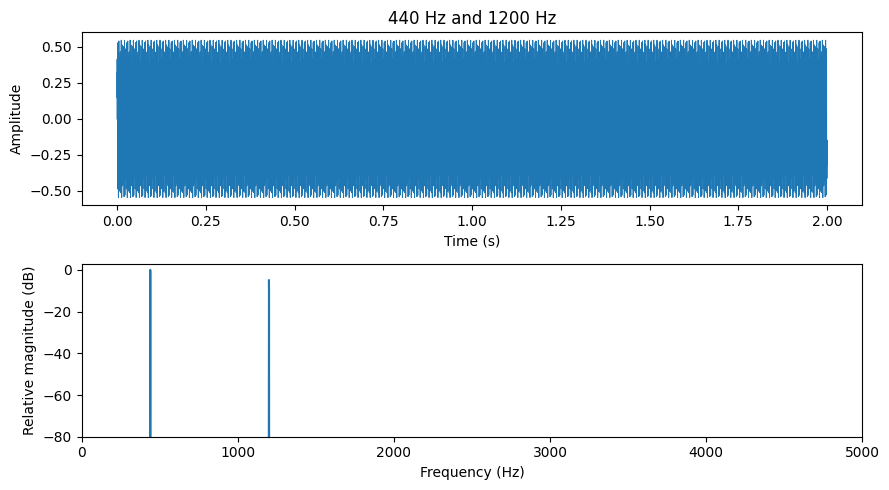

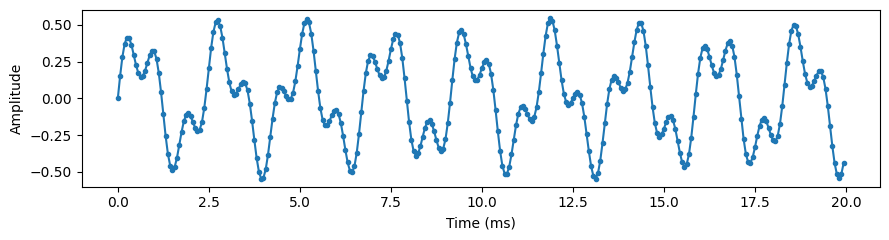

In [3]:
t=np.arange(2*FS)/FS
two_tone=.35*np.sin(2*np.pi*440*t)+.2*np.sin(2*np.pi*1200*t)
sf.write(DATA/'demo/two_tone.wav',two_tone,FS,subtype='PCM_16')
play(two_tone); inspect(two_tone,title='440 Hz and 1200 Hz',name='01_wave_spectrum.png')
n=int(.02*FS)
plt.figure(figsize=(9,2.5));plt.plot(t[:n]*1000,two_tone[:n],'.-');plt.xlabel('Time (ms)');plt.ylabel('Amplitude');save_plot('02_zoom.png')


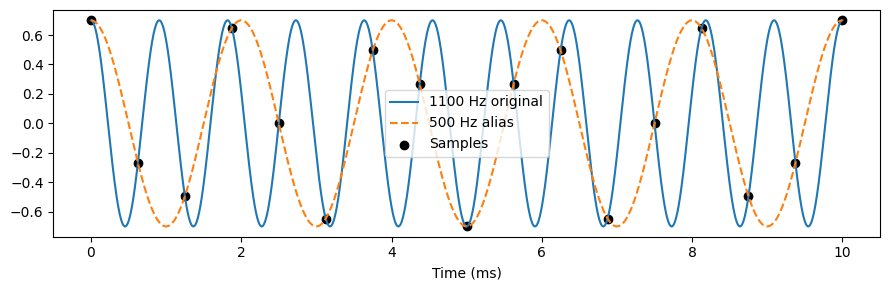

Observed alias: 500.0 Hz


In [4]:
original=1100; fs_alias=1600
st=np.arange(160)/fs_alias
sampled=.7*np.cos(2*np.pi*original*st)
alias=abs((original+fs_alias/2)%fs_alias-fs_alias/2)
fine=np.linspace(0,.01,2000)
plt.figure(figsize=(9,3))
plt.plot(fine*1000,.7*np.cos(2*np.pi*original*fine),label='1100 Hz original')
plt.plot(fine*1000,.7*np.cos(2*np.pi*alias*fine),'--',label=f'{alias:.0f} Hz alias')
v=st<=.01;plt.scatter(st[v]*1000,sampled[v],c='black',label='Samples')
plt.xlabel('Time (ms)');plt.legend();save_plot('03_aliasing.png')
print('Observed alias:',alias,'Hz')
# This intentionally samples without an anti-alias filter. It is not proper resampling.


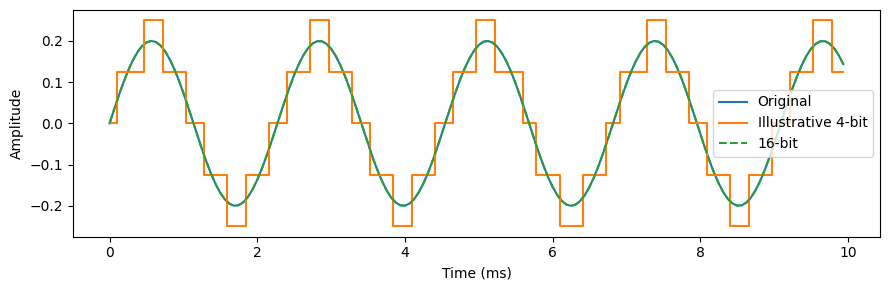

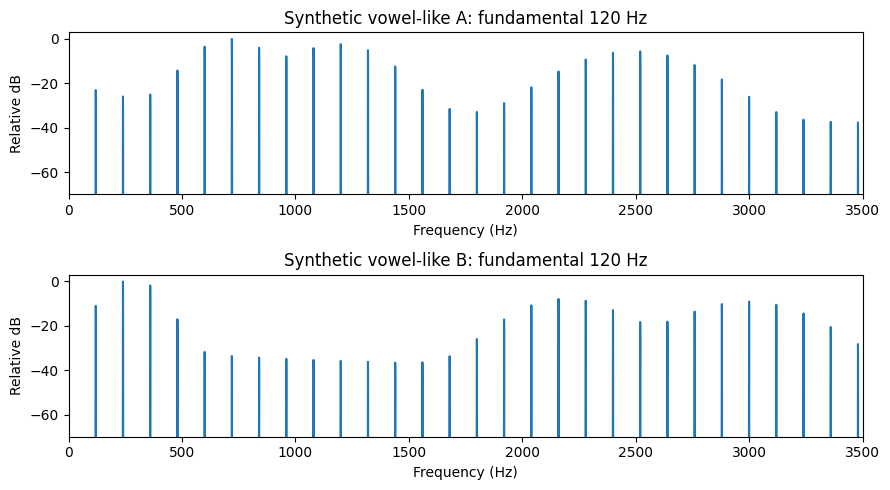

In [5]:
def quantize(x,bits):
    scale=2**(bits-1)
    return np.clip(np.round(x*scale),-scale,scale-1)/scale
quiet=.2*np.sin(2*np.pi*440*t);q4=quantize(quiet,4);q16=quantize(quiet,16)
n=int(.01*FS)
plt.figure(figsize=(9,3));plt.plot(t[:n]*1000,quiet[:n],label='Original')
plt.step(t[:n]*1000,q4[:n],where='mid',label='Illustrative 4-bit');plt.plot(t[:n]*1000,q16[:n],'--',label='16-bit')
plt.xlabel('Time (ms)');plt.ylabel('Amplitude');plt.legend();save_plot('04_quantization.png')
play(q16);play(q4)

def vowel_like(centres):
    x=np.zeros_like(t)
    for k in range(1,41):
        f=k*120
        envelope=.03+sum(np.exp(-.5*((f-c)/w)**2) for c,w in centres)
        x+=envelope/np.sqrt(k)*np.sin(2*np.pi*f*t)
    return .75*x/max(abs(x))
vowel_a=vowel_like([(720,120),(1200,160),(2500,220)])
vowel_b=vowel_like([(300,90),(2200,180),(3000,220)])
fig,axes=plt.subplots(2,1,figsize=(9,5))
for ax,x,title in zip(axes,[vowel_a,vowel_b],['A','B']):
    f,d=spectrum(x);ax.plot(f,d);ax.set(title=f'Synthetic vowel-like {title}: fundamental 120 Hz',xlim=(0,3500),ylim=(-70,3),xlabel='Frequency (Hz)',ylabel='Relative dB')
save_plot('05_vowel_envelopes.png');play(vowel_a);play(vowel_b)


### Task 1 (LO1)
Inspect a dog recording from the supplied manifest. Plot its waveform and spectrum. Write one supported conclusion and one limitation. Do not infer the source from the tallest frequency peak alone. Expected output: two plots and two sentences.


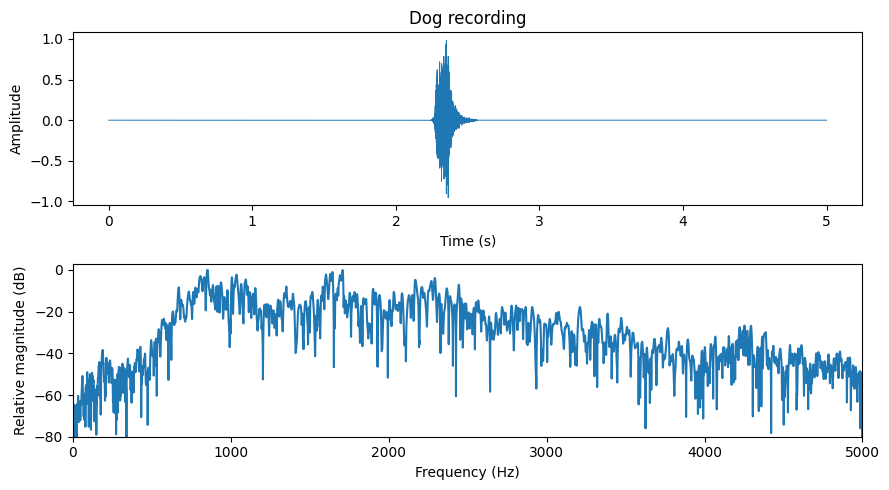

In [6]:
# TODO
dog=load_audio(DATA/'classification/1-100032-A-0.wav')
play(dog)
inspect(dog,title='Dog recording',name='dog_inspection.png')

Supported conclusion:
The Waveform shows one short barking sound at around 2.3 seconds. The strongest frequency are mainly between 750 Hz and 2500 Hz.
Limitation:
The frequency spectrum alsways just shows which frequencies are present, but it does not show when they appear.

## Block 2: spectrograms and features (45–85 minutes)
The short-time Fourier transform (STFT) applies a Fourier transform to successive windows. A spectrogram plots their magnitude or power. A long window separates nearby frequencies more clearly but spreads short events in time. The mel scale redistributes frequency bands using a perceptually motivated spacing. Mel-frequency cepstral coefficients (MFCCs) summarize a log-mel spectrum.

MFCC coefficient index is not frequency in hertz. For classification, pooling means reducing frame-level features to a fixed-length clip representation.


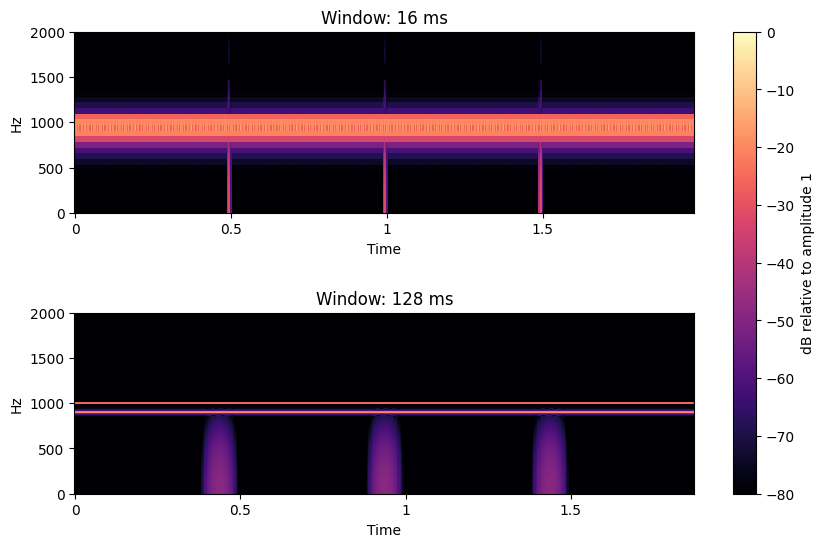

In [7]:
# Controlled example: nearby tones plus short clicks.
tf=np.arange(2*FS)/FS
trade=.2*np.sin(2*np.pi*900*tf)+.2*np.sin(2*np.pi*1000*tf)
for pos in [.5,1,1.5]:
    i=int(pos*FS);trade[i:i+32]+=.25*np.hanning(32)
fig,axes=plt.subplots(2,1,figsize=(10,6));fig.subplots_adjust(hspace=.55)
for ax,nfft in zip(axes,[256,2048]):
    S=np.abs(librosa.stft(trade,n_fft=nfft,hop_length=64,center=False))
    S=S/max(np.hanning(nfft).sum(),1)
    db=librosa.amplitude_to_db(S,ref=1.0)
    im=librosa.display.specshow(db,sr=FS,hop_length=64,x_axis='time',y_axis='linear',ax=ax,vmin=-80,vmax=0)
    ax.set(title=f'Window: {1000*nfft/FS:.0f} ms',ylim=(0,2000))
fig.colorbar(im,ax=axes,label='dB relative to amplitude 1')
plt.savefig(FIG/'06_window_tradeoff.png',dpi=140,bbox_inches='tight');plt.show()


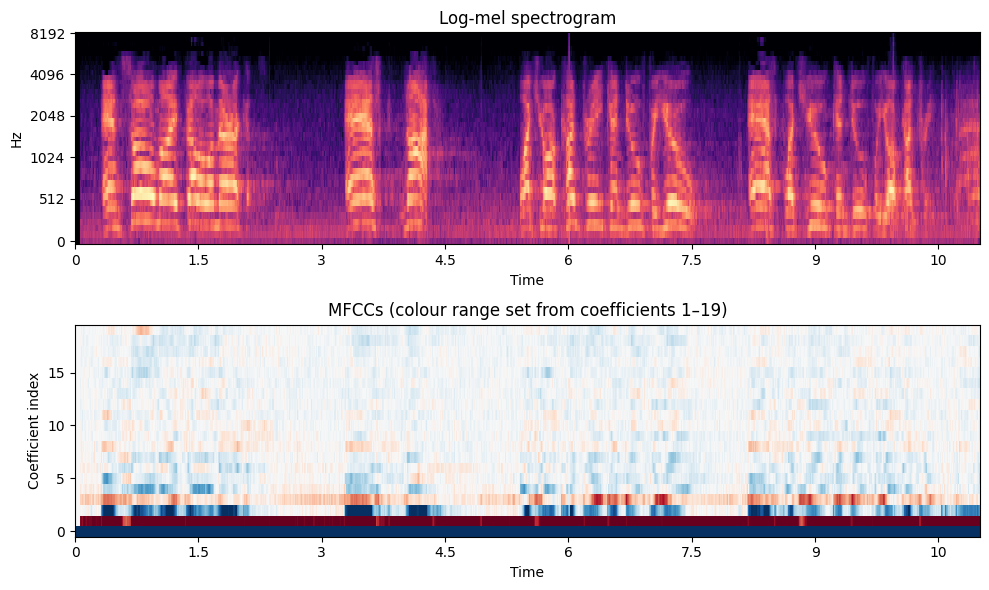

Frame matrix: (20, 1101) Pooled feature vector: (40,)


In [8]:
mel=librosa.feature.melspectrogram(y=speech,sr=FS,n_fft=512,hop_length=160,n_mels=40,power=2)
logmel=librosa.power_to_db(mel,ref=np.max)
mfcc=librosa.feature.mfcc(S=logmel,n_mfcc=20)
fig,ax=plt.subplots(2,1,figsize=(10,6))
librosa.display.specshow(logmel,sr=FS,hop_length=160,x_axis='time',y_axis='mel',ax=ax[0]);ax[0].set_title('Log-mel spectrogram')
limit=np.percentile(np.abs(mfcc[1:]),95)
librosa.display.specshow(mfcc,sr=FS,hop_length=160,x_axis='time',ax=ax[1],cmap='RdBu_r',vmin=-limit,vmax=limit);ax[1].set(title='MFCCs (colour range set from coefficients 1–19)',ylabel='Coefficient index',yticks=[0,5,10,15])
save_plot('07_mel_mfcc.png')
pooled=np.r_[mfcc.mean(axis=1),mfcc.std(axis=1)]
print('Frame matrix:',mfcc.shape,'Pooled feature vector:',pooled.shape)


### Task 2 (LO2)
Compare a 512-sample and a 2048-sample STFT on the same recording. Keep the hop length at 160 samples. Explain which view better separates nearby frequencies and which better locates short events. Extract 20 MFCCs and report the shape before and after mean/std pooling.


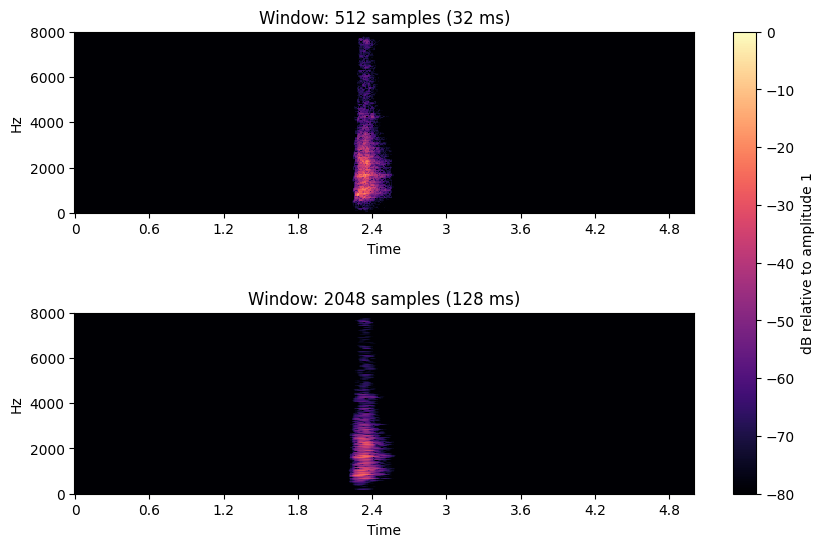

Frame matrix: (20, 501) Pooled feature vector: (40,)


In [9]:
# TODO
# Compare of the STFT window lengths
fig,axes=plt.subplots(2,1,figsize=(10,6))
fig.subplots_adjust(hspace=.55)

for ax,nfft in zip(axes,[512,2048]):
    S=np.abs(librosa.stft(dog,n_fft=nfft,hop_length=160,center=True))
    S=S/max(np.hanning(nfft).sum(),1)
    db=librosa.amplitude_to_db(S,ref=1.0)

    im=librosa.display.specshow(db,sr=FS,hop_length=160,
        x_axis='time',y_axis='linear',ax=ax,vmin=-80,vmax=0)

    ax.set(title=f'Window: {nfft} samples ({1000*nfft/FS:.0f} ms)',
        ylim=(0,8000))

fig.colorbar(im,ax=axes,label='dB relative to amplitude 1')
plt.savefig(FIG/'dog_spectrogram_comparison.png',dpi=140,bbox_inches='tight')
plt.show()

# Extract MFCCs and feature pooling
mel=librosa.feature.melspectrogram(y=dog,sr=FS,n_fft=512,hop_length=160,n_mels=40,power=2)
logmel=librosa.power_to_db(mel,ref=np.max)
mfcc=librosa.feature.mfcc(S=logmel,n_mfcc=20)

pooled=np.r_[mfcc.mean(axis=1),mfcc.std(axis=1)]

print('Frame matrix:',mfcc.shape,'Pooled feature vector:',pooled.shape)

**Break: minutes 85–95.** Save your notebook. Colab temporary files can disappear when the runtime resets.


## Block 3: classical audio processing (95–130 minutes)
A notch attenuates a narrow frequency region. A band-pass retains an interval of frequencies. Spectral gating attenuates time-frequency regions judged to contain mainly noise. None of these methods guarantees improved speech recognition. Listen for removed information and artifacts as well as reduced noise.

The filters below use forward-backward offline processing. This needs future samples, squares the magnitude response and is not the same as a causal embedded implementation.


clean_reference


noisy


notch


telephone


spectral_gate


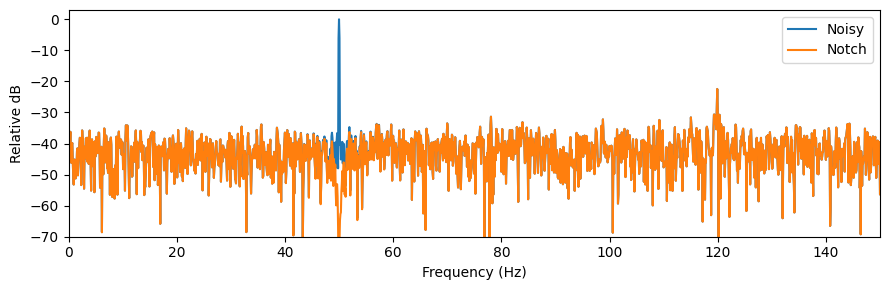

,method,reference_snr_db
0,noisy,4.019221
1,notch,4.807317
2,spectral_gate,6.462851


In [10]:
# Known clean reference, hum and white noise. Include 0.5 seconds of noise-only lead-in.
clean=np.r_[np.zeros(FS//2),speech]
rng=np.random.default_rng(SEED)
noise=rng.normal(size=len(clean));noise*=np.sqrt(np.mean(speech**2))/np.sqrt(np.mean(noise[FS//2:]**2))
noise*=10**(-5/20)  # 5 dB nominal white-noise SNR on active reference interval.
hum=.05*np.sin(2*np.pi*50*np.arange(len(clean))/FS)
common_gain=min(1,.95/np.max(abs(clean+noise+hum)))
clean=clean*common_gain
noisy=(np.r_[np.zeros(FS//2),speech]+noise+hum)*common_gain
b,a=signal.iirnotch(50,Q=30,fs=FS)
notched=signal.filtfilt(b,a,noisy)
sos=signal.butter(4,[300,3400],btype='bandpass',fs=FS,output='sos')
telephone=signal.sosfiltfilt(sos,clean)
import noisereduce as nr
gated=nr.reduce_noise(y=noisy,sr=FS,y_noise=noisy[:FS//2],stationary=True,prop_decrease=.8)
for name,x in [('clean_reference',clean),('noisy',noisy),('notch',notched),('telephone',telephone),('spectral_gate',gated)]:
    sf.write(OUT/(name+'.wav'),x,FS,subtype='FLOAT')
    print(name);play(x)
fig,ax=plt.subplots(1,1,figsize=(9,3))
ref=max(np.abs(np.fft.rfft((noisy-noisy.mean())*np.hanning(len(noisy))))).item()
for name,x in [('Noisy',noisy),('Notch',notched)]:
 f=np.fft.rfftfreq(len(x),1/FS);s=np.abs(np.fft.rfft((x-x.mean())*np.hanning(len(x))));d=20*np.log10(np.maximum(s/ref,1e-6));ax.plot(f,d,label=name)
ax.set(xlim=(0,150),ylim=(-70,3),xlabel='Frequency (Hz)',ylabel='Relative dB');ax.legend();save_plot('08_notch.png')

def reference_snr(reference,estimate):
    # Aligned signals, equal units and gain. No independent peak normalisation.
    reference=np.asarray(reference);estimate=np.asarray(estimate)
    assert reference.shape==estimate.shape
    return 10*np.log10((np.sum(reference**2)+1e-12)/(np.sum((reference-estimate)**2)+1e-12))
processing_results=pd.DataFrame([{'method':name,'reference_snr_db':reference_snr(clean,x)} for name,x in [('noisy',noisy),('notch',notched),('spectral_gate',gated)]])
display(processing_results);processing_results.to_csv(OUT/'processing_metrics.csv',index=False)


### Task 3 (LO3)
Compare spectral-gate strengths 0.5 and 1.0 on the same mixture. Keep the noise estimate fixed. Record one listening observation and the reference-based SNR for each. Explain why stronger suppression need not give better speech quality. The telephone filter is an effect demonstration, not a general denoiser.


In [ ]:
# TODO


## Block 4: build and compare sound classifiers (130–175 minutes)
A classifier maps an input representation to a class label. A support vector machine (SVM) learns decision boundaries. A pretrained embedding is a feature vector produced by a model trained earlier on other data. Logistic regression is a supervised classifier despite its name.

The supplied small dataset has four environmental classes: dog, rain, crackling_fire and clock_tick. It is a classroom exercise, not a production benchmark. The team's clap/snap/speech/background recordings can replace it through a separate manifest. Split by original recording or team before creating crops or augmentations.

Use training data to fit parameters, validation data for choices and test data for the final comparison. Both pipelines use the same partitions. ESC-50 may overlap with material seen in pretraining; this is not a verified pretraining-independent transfer benchmark.


In [11]:
manifest=pd.read_csv(DATA/'manifest.csv')
assert set(manifest.split)=={'train','validation','test'}
assert manifest.groupby('group').split.nunique().max()==1, 'Source leakage across partitions.'
classes=sorted(manifest.label.unique())
for part in ['train','validation','test']:
    assert set(manifest[manifest.split==part].label)==set(classes), 'Missing class in a partition.'
display(pd.crosstab(manifest.label,manifest.split))

def mfcc_vector(x):
    M=librosa.feature.mfcc(y=x,sr=FS,n_mfcc=20,n_fft=512,hop_length=160,n_mels=40)
    return np.r_[M.mean(axis=1),M.std(axis=1)]
clips=[load_audio(DATA/r.file) for r in manifest.itertuples()]
start=time.perf_counter()
X_mfcc=np.stack([mfcc_vector(x) for x in clips])
mfcc_feature_seconds=time.perf_counter()-start
y=manifest.label.to_numpy()
train=manifest.split.eq('train').to_numpy();valid=manifest.split.eq('validation').to_numpy();test=manifest.split.eq('test').to_numpy()
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
mfcc_classifier=make_pipeline(StandardScaler(),SVC(C=1,kernel='rbf',class_weight='balanced',random_state=SEED))
mfcc_classifier.fit(X_mfcc[train],y[train])
print('Validation: MFCC + SVM')
print(classification_report(y[valid],mfcc_classifier.predict(X_mfcc[valid]),labels=classes,zero_division=0))
print('Feature matrix:',X_mfcc.shape,'Extraction seconds:',round(mfcc_feature_seconds,2))


split,test,train,validation
label,,,
clock_tick,2,6,2
crackling_fire,2,6,2
dog,2,6,2
rain,2,6,2


Validation: MFCC + SVM
                precision    recall  f1-score   support

    clock_tick       0.50      0.50      0.50         2
crackling_fire       1.00      1.00      1.00         2
           dog       0.50      0.50      0.50         2
          rain       1.00      1.00      1.00         2

      accuracy                           0.75         8
     macro avg       0.75      0.75      0.75         8
  weighted avg       0.75      0.75      0.75         8

Feature matrix: (40, 40) Extraction seconds: 0.67


In [12]:
# Frozen YAMNet feature extractor. Network/model download may take time on first use.
# For a precomputed classroom route, set USE_EMBEDDING_CACHE=True.
# A cache is valid only for the supplied, unchanged manifest and files.
import hashlib
USE_EMBEDDING_CACHE=True

def dataset_digest():
    h=hashlib.sha256((DATA/'manifest.csv').read_bytes())
    for r in manifest.itertuples():h.update((DATA/r.file).read_bytes())
    return h.hexdigest()
cache=DATA/'yamnet_cache.npz'
if USE_EMBEDDING_CACHE and cache.exists():
    z=np.load(cache,allow_pickle=False)
    assert z['dataset_sha256'].item()==dataset_digest(), 'Cache belongs to a different dataset.'
    X_embed=z['embeddings'];embedding_seconds=float(z['extraction_seconds'])
    print('Using previously measured YAMNet embeddings. This is cached inference, not a new model run.')
else:
    import tensorflow as tf
    import tensorflow_hub as hub
    tf.config.set_visible_devices([], 'GPU')
    yamnet=hub.load('https://tfhub.dev/google/yamnet/1')
    vectors=[];start=time.perf_counter()
    for x in clips:
        scores,embeddings,log_mel=yamnet(tf.convert_to_tensor(x,dtype=tf.float32))
        vectors.append(embeddings.numpy().mean(axis=0))
    embedding_seconds=time.perf_counter()-start
    X_embed=np.stack(vectors)
    np.savez(cache,embeddings=X_embed,dataset_sha256=dataset_digest(),extraction_seconds=embedding_seconds)
embed_classifier=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000,class_weight='balanced',random_state=SEED))
embed_classifier.fit(X_embed[train],y[train])
print('Validation: YAMNet + logistic regression')
print(classification_report(y[valid],embed_classifier.predict(X_embed[valid]),labels=classes,zero_division=0))
print('Embedding matrix:',X_embed.shape)


Using previously measured YAMNet embeddings. This is cached inference, not a new model run.
Validation: YAMNet + logistic regression
                precision    recall  f1-score   support

    clock_tick       1.00      1.00      1.00         2
crackling_fire       0.67      1.00      0.80         2
           dog       1.00      0.50      0.67         2
          rain       1.00      1.00      1.00         2

      accuracy                           0.88         8
     macro avg       0.92      0.88      0.87         8
  weighted avg       0.92      0.88      0.87         8

Embedding matrix: (40, 1024)


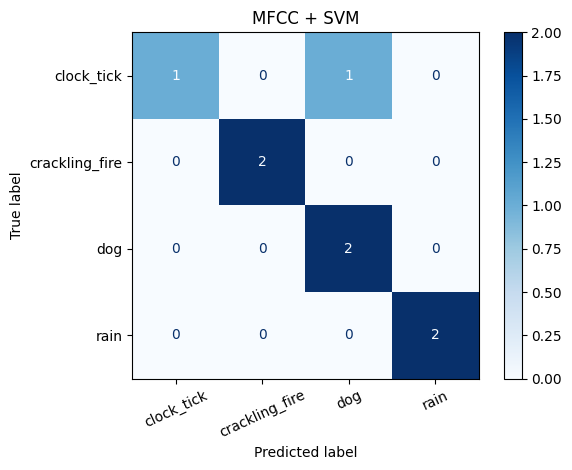

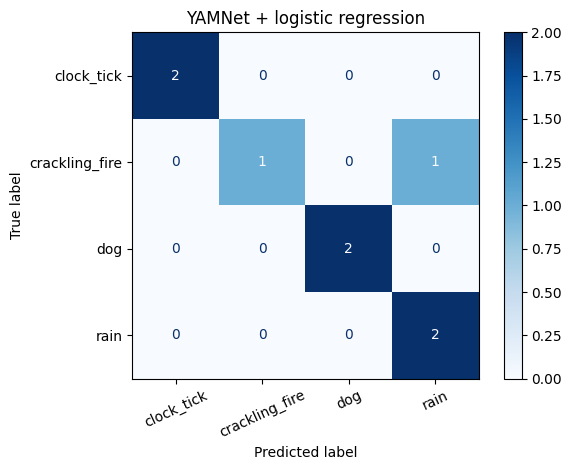

,pipeline,test_accuracy,test_macro_f1,feature_seconds_all_clips,classifier_prediction_seconds_test
0,MFCC + SVM,0.875,0.866667,0.670624,0.014286
1,YAMNet + logistic regression,0.875,0.866667,1.130144,0.003314


The two pipelines change both representation and classifier. This is not an isolated test of representation alone.


In [13]:
# Run once after deciding settings. Do not tune on these test results.
comparisons=[]
for name,model,X,feature_seconds in [('MFCC + SVM',mfcc_classifier,X_mfcc,mfcc_feature_seconds),('YAMNet + logistic regression',embed_classifier,X_embed,embedding_seconds)]:
    start=time.perf_counter();prediction=model.predict(X[test]);predict_seconds=time.perf_counter()-start
    comparisons.append({'pipeline':name,'test_accuracy':accuracy_score(y[test],prediction),'test_macro_f1':f1_score(y[test],prediction,labels=classes,average='macro',zero_division=0),'feature_seconds_all_clips':feature_seconds,'classifier_prediction_seconds_test':predict_seconds})
    ConfusionMatrixDisplay.from_predictions(y[test],prediction,labels=classes,xticks_rotation=25,cmap='Blues')
    plt.title(name);save_plot('09_'+('mfcc' if name.startswith('MFCC') else 'yamnet')+'_confusion.png')
    rows=manifest.loc[test,['file','label','group','split']].copy();rows['prediction']=prediction;rows.to_csv(OUT/('predictions_'+('mfcc' if name.startswith('MFCC') else 'yamnet')+'.csv'),index=False)
comparison=pd.DataFrame(comparisons);display(comparison);comparison.to_csv(OUT/'classifier_comparison.csv',index=False)
print('The two pipelines change both representation and classifier. This is not an isolated test of representation alone.')


### Task 4 (LO2, LO4)
Explain one confusion-matrix entry. Choose one misclassified test clip, or a correctly classified clip if there are no errors, and listen to it. Suggest a follow-up experiment without using the current test set for tuning. State why embeddings and a new classifier do not mean that YAMNet was trained on your labels.

Optional extension: compare both representations with logistic regression using the same train/validation splits. This better isolates representation, but a small dataset still limits the conclusion.


In [ ]:
# TODO


**Break: minutes 175–185.** The instructor prepares the model-output comparisons. Students save the results CSV files.


## Block 5: ready-made audio tools (185–210 minutes)
Automatic speech recognition (ASR) maps speech to words. Word error rate (WER) counts substitutions, deletions and insertions relative to the reference word count. Apply the same text normalisation to both texts. Lower WER is better; WER can exceed 100%.

Whisper runs on the Colab CPU. English audio is supplied. The optional upload cell supports a Finnish or Turkish recording with its own reference. Do not set a language code that disagrees with the audio. The supplied English file is the no-microphone fallback.

A neural speech denoiser estimates cleaner speech. Hybrid Demucs separates a music mixture into source stems. A music separator is not a general-purpose speech denoiser. Downloads and inference are instructor preparation, not a requirement to finish within this 25-minute block.


In [14]:
def normalise_text(text):
    text=unicodedata.normalize('NFKC',text).casefold()
    return ' '.join(re.sub(r'[^\w\s]','',text).split())

def wer_details(reference,hypothesis):
    r=normalise_text(reference).split();h=normalise_text(hypothesis).split()
    assert r, 'WER needs a non-empty reference. Analyse silence separately.'
    d=np.zeros((len(r)+1,len(h)+1),dtype=int)
    d[:,0]=np.arange(len(r)+1);d[0,:]=np.arange(len(h)+1)
    for i in range(1,len(r)+1):
        for j in range(1,len(h)+1):d[i,j]=min(d[i-1,j]+1,d[i,j-1]+1,d[i-1,j-1]+(r[i-1]!=h[j-1]))
    i,j=len(r),len(h);S=D=I=0
    while i or j:
        if i and j and r[i-1]==h[j-1] and d[i,j]==d[i-1,j-1]:i-=1;j-=1
        elif i and j and d[i,j]==d[i-1,j-1]+1:S+=1;i-=1;j-=1
        elif i and d[i,j]==d[i-1,j]+1:D+=1;i-=1
        else:I+=1;j-=1
    return {'S':S,'D':D,'I':I,'N':len(r),'WER':float(d[-1,-1]/len(r))}

RUN_WHISPER=True
if RUN_WHISPER:
    import torch,whisper
    torch.set_num_threads(2)
    asr=whisper.load_model('tiny',device='cpu')
    opts=dict(language='en',task='transcribe',fp16=False,temperature=0,condition_on_previous_text=False,verbose=None)
    asr.transcribe(np.asarray(clean,dtype=np.float32),**opts)  # warm-up outside timing
    reference=(DATA/'demo/speech_reference.txt').read_text().strip()
    asr_rows=[]
    for name,x in [('clean',clean),('noisy',noisy),('spectral_gate',gated)]:
        start=time.perf_counter();text=asr.transcribe(np.asarray(x,dtype=np.float32),**opts)['text'];elapsed=time.perf_counter()-start
        row=dict(condition=name,reference=reference,prediction=text,inference_seconds=elapsed,RTF=elapsed/(len(x)/FS),**wer_details(reference,text));asr_rows.append(row)
    display(pd.DataFrame(asr_rows));pd.DataFrame(asr_rows).to_csv(OUT/'asr_comparison.csv',index=False)


100%|██████████████████████████████████████| 72.1M/72.1M [00:00<00:00, 144MiB/s]


,condition,reference,prediction,inference_seconds,RTF,S,D,I,N,WER
0,clean,And so my fellow Americans ask not what your c...,And so my fellow Americans ask not what your ...,1.293513,0.112479,0,0,0,22,0.000000
1,noisy,And so my fellow Americans ask not what your c...,"And so my fellow American, and not what your ...",1.330209,0.115670,3,0,0,22,0.136364
2,spectral_gate,And so my fellow Americans ask not what your c...,"And so my fellow American, and not what your ...",1.369434,0.119081,3,0,0,22,0.136364


In [16]:
# Optional Finnish/Turkish example. Leave False for the supplied English route.
RUN_LANGUAGE_UPLOAD=False
if RUN_LANGUAGE_UPLOAD:
    from google.colab import files
    uploads=files.upload();names=[n for n in uploads if n.lower().endswith('.wav')]
    assert len(names)==1, 'Upload one short speech WAV.'
    language=input('Spoken language code: en, fi or tr: ').strip()
    assert language in ['en','fi','tr']
    reference_local=input('Actual spoken words: ').strip()
    x=load_audio(names[0]);assert len(x)/FS<=15
    if 'asr' not in globals():
        import whisper
        asr=whisper.load_model('tiny',device='cpu')
    text=asr.transcribe(x,language=language,task='transcribe',fp16=False,temperature=0,verbose=None)['text']
    print('Prediction:',text);print(wer_details(reference_local,text))


In [17]:
# Neural denoiser: prepare before class. It is separate from music source separation.
RUN_NEURAL_DENOISER=True
if RUN_NEURAL_DENOISER:
    import torch
    torch.set_num_threads(2)
    denoiser=torch.hub.load('facebookresearch/denoiser:8afd7c166699bb3c8b2d95b6dd706f71e1075df0','dns64',pretrained=True,trust_repo=True).cpu().eval()
    assert denoiser.sample_rate==FS
    with torch.no_grad():
        neural=denoiser(torch.from_numpy(noisy.astype(np.float32))[None,None,:])[0,0].numpy()
    neural=neural[:len(clean)]
    sf.write(OUT/'neural_denoised.wav',neural,FS,subtype='FLOAT')
    for name,x in [('Noisy',noisy),('Spectral gate',gated),('Neural denoiser',neural)]:
        print(name,'reference SNR:',reference_snr(clean,x));play(x)
    if 'asr' in globals():
        text=asr.transcribe(neural.astype(np.float32),**opts)['text']
        print('Neural output transcript:',text);print(wer_details(reference,text))


Downloading: "https://github.com/facebookresearch/denoiser/zipball/8afd7c166699bb3c8b2d95b6dd706f71e1075df0" to /root/.cache/torch/hub/8afd7c166699bb3c8b2d95b6dd706f71e1075df0.zip
Downloading: "https://dl.fbaipublicfiles.com/adiyoss/denoiser/dns64-a7761ff99a7d5bb6.th" to /root/.cache/torch/hub/checkpoints/dns64-a7761ff99a7d5bb6.th
100%|██████████| 128M/128M [00:00<00:00, 196MB/s]


Noisy reference SNR: 4.019221453196627


Spectral gate reference SNR: 6.462850526368059


Neural denoiser reference SNR: 13.510505948801208


Neural output transcript:  And so my fellow nerds, ask not what's your country's and tools for you, ask what you's and tools for your country.
{'S': 8, 'D': 0, 'I': 0, 'N': 22, 'WER': 0.36363636363636365}


### Hybrid Demucs: instructor demonstration
The following cell uses the official TorchAudio pretrained Hybrid Demucs implementation. It avoids installing the archived standalone Demucs package with its older TorchAudio constraints. Input: a short stereo music excerpt. Outputs: drums, bass, other and vocals. These are estimates. A stem name does not prove that its output is clean or complete.

The example excerpt is from the TorchAudio tutorial: A Classic Education — NightOwl, MedleyDB, CC BY-NC-SA 4.0. Source and attribution are in the package. If preparation fails, use the official tutorial playback and explicitly identify it as a source demonstration, not your measured result.


In [ ]:
RUN_DEMUCS=True
if RUN_DEMUCS:
    import torch,torchaudio
    import urllib.request
    torch.set_num_threads(2)
    music_path=DATA/'demo/music_excerpt.wav'
    if not music_path.exists():
        original=DATA/'demo/hdemucs_mix.wav'
        urllib.request.urlretrieve('https://download.pytorch.org/torchaudio/tutorial-assets/hdemucs_mix.wav',original)
        music,rate=sf.read(original,always_2d=True,dtype='float32')
        music=music[:int(5*rate)]
        sf.write(music_path,music,rate,subtype='FLOAT')
    music,rate=sf.read(music_path,always_2d=True,dtype='float32')
    bundle=torchaudio.pipelines.HDEMUCS_HIGH_MUSDB_PLUS
    separator=bundle.get_model().cpu().eval()
    assert rate==bundle.sample_rate and music.shape[1]==2
    wav=torch.from_numpy(music.T.copy())
    ref=wav.mean(0);mean=ref.mean();std=ref.std().clamp_min(1e-6)
    with torch.no_grad():stems=separator(((wav-mean)/std)[None])[0]*std+mean
    print('Original mixture');display(Audio(music.T,rate=rate,normalize=False))
    for name,stem in zip(separator.sources,stems):
        sf.write(OUT/f'demucs_{name}.wav',stem.T.numpy(),rate,subtype='FLOAT')
        print(name);display(Audio(stem.numpy(),rate=rate,normalize=False))


### Task 5 (LO3, LO5)
Compare the noisy, spectral-gate and neural-denoiser outputs. State one listening observation and one limitation of the metric. Calculate WER for the reference “send the final report” and prediction “send a report”. If model inference is unavailable, the manual WER exercise and classical comparison remain runnable. Do not invent a neural result.


In [ ]:
# TODO


## Mini project (210–235 minutes)
Use one of the three briefs in Mini_Project.md. Five teams of four. Work for 15 minutes, then present for two minutes per team. Reuse existing results and models. Do not train a new neural network or start large downloads during this activity.

Required evidence: question, fixed comparison, plot or table, one limitation. Assign roles: operator, evaluator, recorder and presenter. Save results under a team-specific folder.


In [ ]:
# TODO


## Wrap-up (235–240 minutes)
Show one outcome with evidence. Name one failed or uncertain case. Explain one change needed for an ESP32 deployment. Finish the quiz after the session if time is short. Download results; do not depend on Colab temporary storage.


In [ ]:
import shutil
archive=shutil.make_archive(str(ROOT/'course_results'),'zip',OUT)
print('Results archive:',archive)
if 'google.colab' in __import__('sys').modules:
    from google.colab import files
    files.download(archive)
